In [2]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Dataset location
root = Path(r"D:\AMME5710_Major_Project\dataset")
split = "train"

# Check dataset
print("Dataset exists:", root.exists())
print("A folder:", (root / split / "A").exists())
print("B folder:", (root / split / "B").exists())
print("OUT folder:", (root / split / "OUT").exists())


Dataset exists: True
A folder: True
B folder: True
OUT folder: True


In [51]:
# Select defect category and image
defect_type = "line"
sample_index = 0

files = sorted(
    (root / split / "B").glob(f"{defect_type}_*.png")
)

if not files:
    raise FileNotFoundError("No matching images found.")

filename = files[sample_index].name
print("Selected:", filename)

# Read reference, defective image and ground truth
A = cv2.imread(str(root / split / "A" / filename))
B = cv2.imread(str(root / split / "B" / filename))

GT = cv2.imread(
    str(root / split / "OUT" / filename),
    cv2.IMREAD_GRAYSCALE
)

if A is None or B is None or GT is None:
    raise FileNotFoundError("Failed to read image pair or mask.")

assert A.shape == B.shape
assert A.shape[:2] == GT.shape

print("Image shape:", A.shape)
print("Mask values:", np.unique(GT))


Selected: line_proofrog_a4pera_back_00010_0011.png
Image shape: (256, 256, 3)
Mask values: [  0   1   2   4   5   6   8   9  12  14  15  17  21  24  25  28  30  32
  33  34  37  38  39  43  45  46  47  48  50  52  62  63  71  73  75  76
  84  90  92  94  97  99 100 102 109 110 112 114 118 121 123 126 130 132
 135 136 137 140 141 142 147 151 152 155 157 158 161 166 168 169 172 173
 174 175 178 182 187 191 192 197 199 200 202 203 210 211 212 213 214 215
 218 220 221 224 226 228 231 232 233 236 237 238 239 240 242 244 250 253
 254 255]


In [52]:
# Convert images to grayscale
gray_A = cv2.cvtColor(A, cv2.COLOR_BGR2GRAY)
gray_B = cv2.cvtColor(B, cv2.COLOR_BGR2GRAY)

# Calculate absolute difference
diff = cv2.absdiff(gray_A, gray_B)

# Apply threshold
T = 20
_, pred = cv2.threshold(
    diff,
    T,
    255,
    cv2.THRESH_BINARY
)

print("Difference shape:", diff.shape)
print("Prediction shape:", pred.shape)

Difference shape: (256, 256)
Prediction shape: (256, 256)


In [53]:
# Convert masks to Boolean
gt_mask = GT > 0
pred_mask = pred > 0

# Count pixel classifications
TP = np.sum(pred_mask & gt_mask)
FP = np.sum(pred_mask & ~gt_mask)
FN = np.sum(~pred_mask & gt_mask)

# Evaluation metrics
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

iou = TP / (TP + FP + FN) if (TP + FP + FN) > 0 else 0

print(f"TP:        {TP}")
print(f"FP:        {FP}")
print(f"FN:        {FN}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"IoU:       {iou:.4f}")

TP:        2
FP:        1256
FN:        346
Precision: 0.0016
Recall:    0.0057
F1-score:  0.0025
IoU:       0.0012


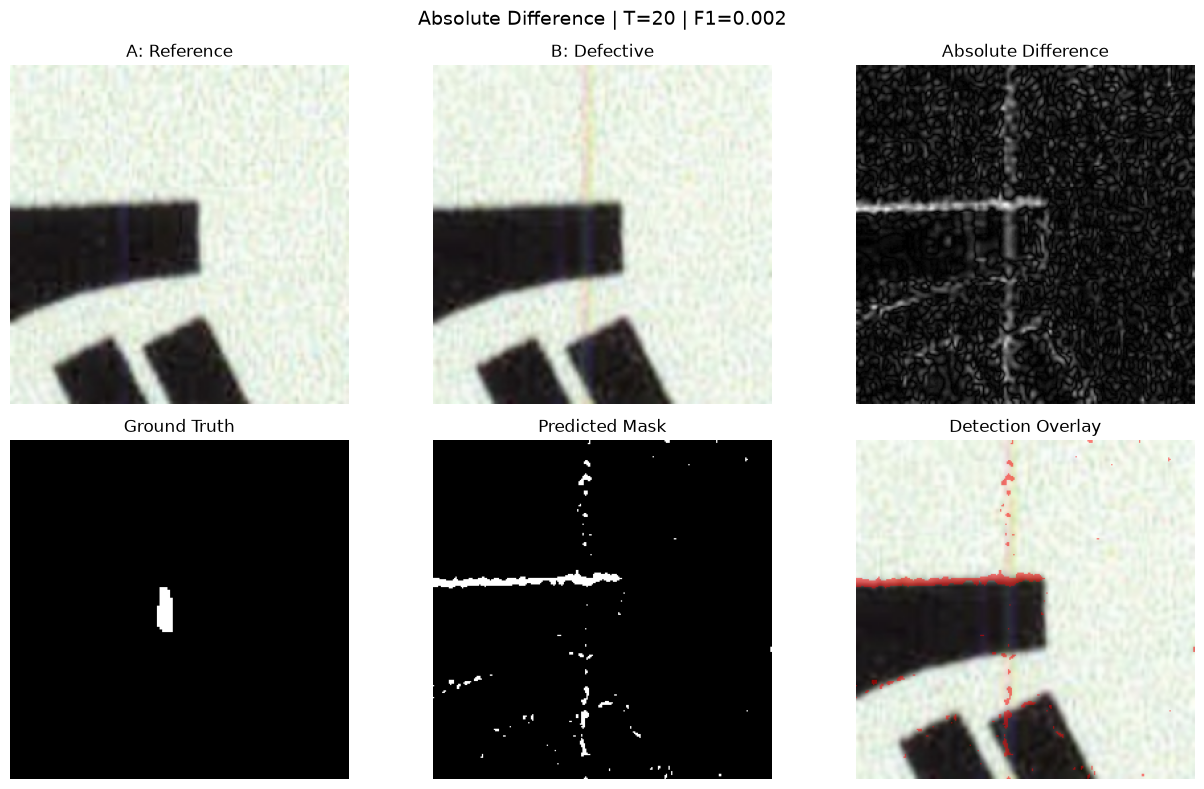

In [54]:
# Convert BGR to RGB for Matplotlib
A_rgb = cv2.cvtColor(A, cv2.COLOR_BGR2RGB)
B_rgb = cv2.cvtColor(B, cv2.COLOR_BGR2RGB)

# Highlight predicted defects in red
overlay = B_rgb.copy()

overlay[pred_mask] = (
    0.5 * B_rgb[pred_mask] +
    0.5 * np.array([255, 0, 0])
).astype(np.uint8)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

images = [
    A_rgb,
    B_rgb,
    diff,
    gt_mask,
    pred_mask,
    overlay
]

titles = [
    "A: Reference",
    "B: Defective",
    "Absolute Difference",
    "Ground Truth",
    "Predicted Mask",
    "Detection Overlay"
]

for ax, img, title in zip(axes.flat, images, titles):
    if img.ndim == 2:
        ax.imshow(img, cmap="gray")
    else:
        ax.imshow(img)

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"Absolute Difference | T={T} | F1={f1:.3f}",
    fontsize=14
)

plt.tight_layout()
plt.show()

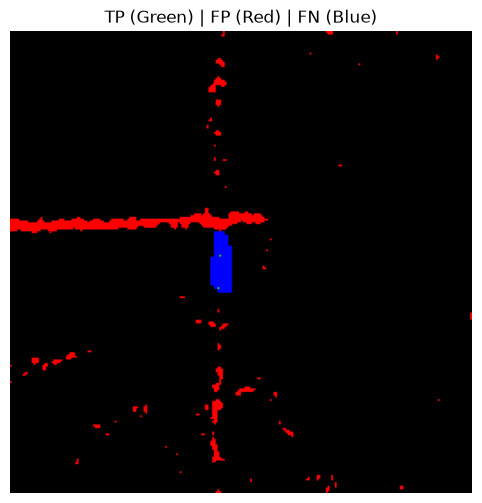

In [55]:
# Visualise TP, FP and FN separately

TP_mask = pred_mask & gt_mask
FP_mask = pred_mask & ~gt_mask
FN_mask = ~pred_mask & gt_mask

result = np.zeros((*gt_mask.shape, 3), dtype=np.uint8)

# Green: correctly detected defect
result[TP_mask] = [0, 255, 0]

# Red: false positive
result[FP_mask] = [255, 0, 0]

# Blue: missed defect
result[FN_mask] = [0, 0, 255]

plt.figure(figsize=(6, 6))
plt.imshow(result)
plt.title("TP (Green) | FP (Red) | FN (Blue)")
plt.axis("off")
plt.show()

Best threshold: 15
Best F1-score: 0.0773


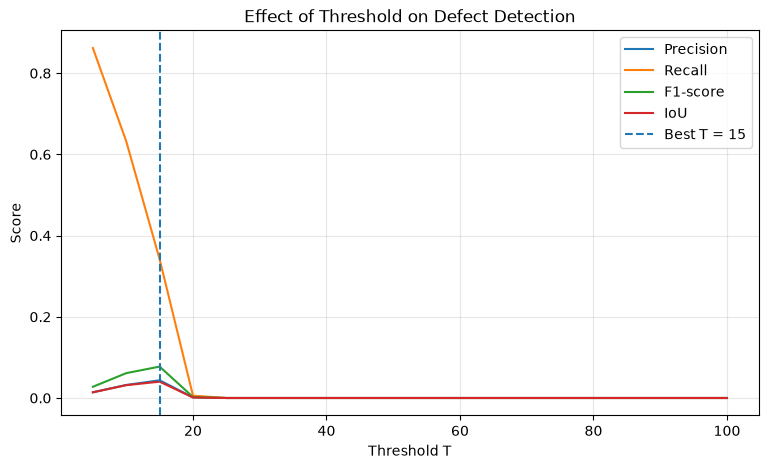

In [56]:

# Test multiple thresholds on the current image

thresholds = range(5, 101, 5)

precision_list = []
recall_list = []
f1_list = []
iou_list = []

for t in thresholds:

    _, current_pred = cv2.threshold(
        diff, t, 255, cv2.THRESH_BINARY
    )

    current_pred_mask = current_pred > 0
    gt_mask = GT > 0

    TP = np.sum(current_pred_mask & gt_mask)
    FP = np.sum(current_pred_mask & ~gt_mask)
    FN = np.sum(~current_pred_mask & gt_mask)

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    iou = (
        TP / (TP + FP + FN)
        if TP + FP + FN > 0 else 0
    )

    precision_list.append(precision)
    recall_list.append(recall)
    f1_list.append(f1)
    iou_list.append(iou)

# Find the threshold with the highest F1
best_index = np.argmax(f1_list)
best_T = list(thresholds)[best_index]

print("Best threshold:", best_T)
print("Best F1-score:", round(f1_list[best_index], 4))

# Plot results
plt.figure(figsize=(9, 5))

plt.plot(thresholds, precision_list, label="Precision")
plt.plot(thresholds, recall_list, label="Recall")
plt.plot(thresholds, f1_list, label="F1-score")
plt.plot(thresholds, iou_list, label="IoU")

plt.axvline(best_T, linestyle="--", label=f"Best T = {best_T}")

plt.xlabel("Threshold T")
plt.ylabel("Score")
plt.title("Effect of Threshold on Defect Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Image: line_proofrog_a4pera_back_00010_0011.png
RGB Precision: 0.0679
RGB Recall:    0.7557
RGB F1:        0.1247
RGB IoU:       0.0665


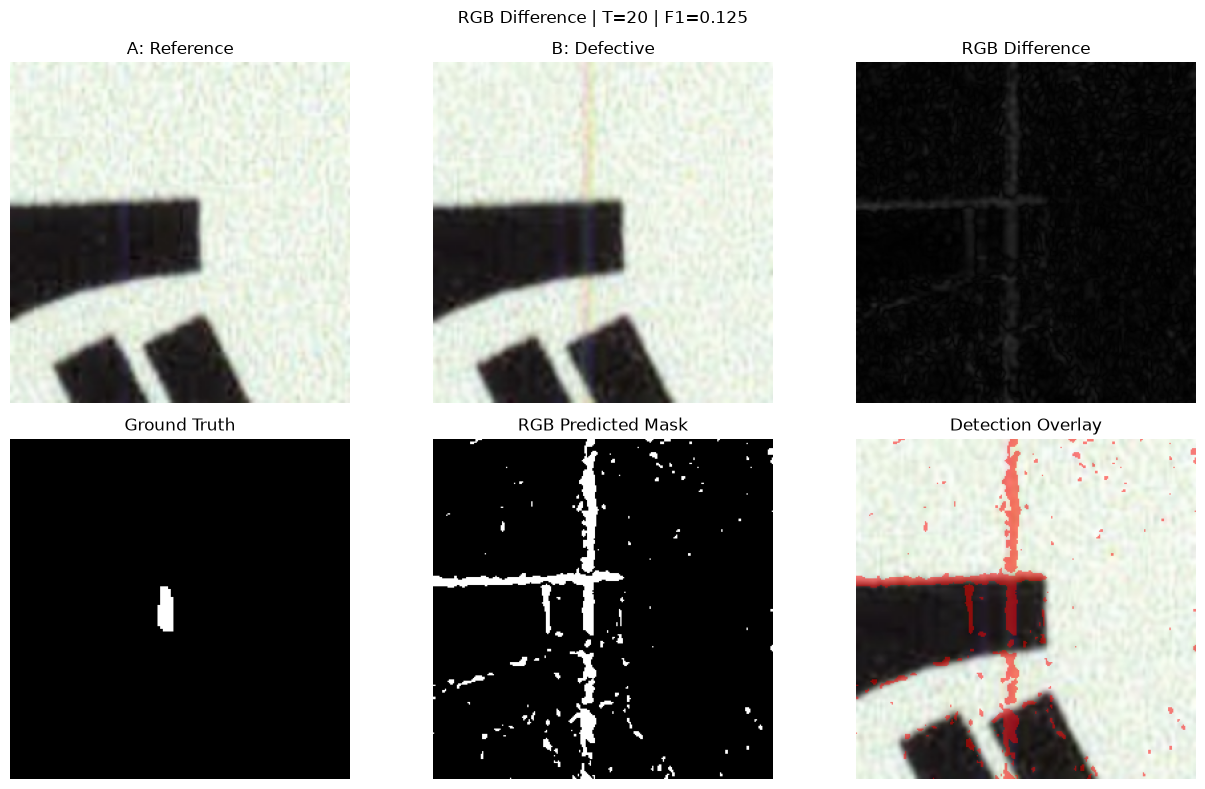

In [57]:

# RGB Colour Difference - Single Image Test

# Calculate absolute difference in all three channels
rgb_diff_3ch = cv2.absdiff(A, B)

# Take the maximum difference among B, G, R
rgb_diff = np.max(rgb_diff_3ch, axis=2)

# Initial threshold
T_rgb = 20
rgb_pred_mask = rgb_diff > T_rgb

# Ground truth
rgb_gt_mask = GT > 0

# Evaluation
tp = np.count_nonzero(rgb_pred_mask & rgb_gt_mask)
fp = np.count_nonzero(rgb_pred_mask & ~rgb_gt_mask)
fn = np.count_nonzero(~rgb_pred_mask & rgb_gt_mask)

precision_rgb = tp / (tp + fp) if tp + fp > 0 else 0
recall_rgb = tp / (tp + fn) if tp + fn > 0 else 0
f1_rgb = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn > 0 else 0
iou_rgb = tp / (tp + fp + fn) if tp + fp + fn > 0 else 0

print("Image:", filename)
print(f"RGB Precision: {precision_rgb:.4f}")
print(f"RGB Recall:    {recall_rgb:.4f}")
print(f"RGB F1:        {f1_rgb:.4f}")
print(f"RGB IoU:       {iou_rgb:.4f}")

# Visual comparison
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

images = [
    cv2.cvtColor(A, cv2.COLOR_BGR2RGB),
    cv2.cvtColor(B, cv2.COLOR_BGR2RGB),
    rgb_diff,
    rgb_gt_mask,
    rgb_pred_mask,
    cv2.cvtColor(B, cv2.COLOR_BGR2RGB)
]

titles = [
    "A: Reference",
    "B: Defective",
    "RGB Difference",
    "Ground Truth",
    "RGB Predicted Mask",
    "Detection Overlay"
]

# Red overlay for predicted defect regions
images[5] = images[5].copy()
images[5][rgb_pred_mask] = (
    0.5 * images[5][rgb_pred_mask] +
    0.5 * np.array([255, 0, 0])
).astype(np.uint8)

for ax, img, title in zip(axes.flat, images, titles):
    if img.ndim == 2:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255 if img.dtype == np.uint8 else 1)
    else:
        ax.imshow(img)

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"RGB Difference | T={T_rgb} | F1={f1_rgb:.3f}"
)
plt.tight_layout()
plt.show()
